# Medicare Price Negotiation: Which Manufacturers Are Most Exposed, and Who Is Next?

**Business question:** The Inflation Reduction Act (IRA) lets Medicare set a
"maximum fair price" (MFP) for high-spend drugs. For a manufacturer's market
access and finance teams: how much Medicare revenue is already under negotiated
prices, who carries the most, and which drugs are likely to be picked in the
next selection round (February 2027)?

**Data:**
- CMS Medicare Part D and Part B Spending by Drug (annual, by manufacturer)
- CMS lists of selected drugs and their negotiated prices (`negotiation_lists.py`)
- openFDA Drugs@FDA approval history (application type, first approval, generic approvals)

**Terms:**
- **Part D** covers drugs patients collect at a pharmacy. **Part B** covers drugs
  given in a clinic or hospital outpatient setting (infusions, injections).
- **IPAY** (initial price applicability year) is the year a negotiated price takes effect.
- **Gross spend** is what Medicare plans and patients paid before manufacturer
  rebates. It overstates manufacturer revenue, which is why section 3 calibrates
  to CMS's own net savings estimates.

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd() if Path.cwd().name.startswith("02-") else Path("02-ira-negotiation-exposure")
sys.path.insert(0, str(HERE.parent))
sys.path.insert(0, str(HERE))
from common import style  # noqa: E402
from negotiation_lists import SELECTED, CMS_CYCLE_SAVINGS  # noqa: E402

style.apply()
SHARED = HERE.parent / "data" / "shared"
RAW, FIG, TAB = HERE / "data" / "raw", HERE / "outputs" / "figures", HERE / "outputs" / "tables"
TAB.mkdir(parents=True, exist_ok=True)
SRC = "CMS Medicare Part D and Part B Spending by Drug; CMS negotiation announcements"


def load_spend(path: Path, part: str) -> pd.DataFrame:
    df = pd.read_csv(path, dtype=str)
    for c in df.columns:
        if re.match(r"(Tot_|Avg_)", c):
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["part"] = part
    df["Brnd_Name"] = df["Brnd_Name"].fillna("").str.replace(r"\*|\(.*?\)", "", regex=True).str.strip()
    if "Mftr_Name" in df:   # Part D: an 'Overall' row per drug plus one row per manufacturer
        df["mftr"] = df["Mftr_Name"].str.strip()
        df["is_overall"] = df["mftr"].str.lower() == "overall"
    else:                   # Part B: one row per billing code, no manufacturer split
        df["mftr"] = None
        df["is_overall"] = df["Gnrc_Name"].notna()
    return df


d = load_spend(SHARED / "partd_spending_by_drug.csv.gz", "D")
b = load_spend(SHARED / "partb_spending_by_drug.csv.gz", "B")
YEARS = sorted(int(c[-4:]) for c in d.columns if re.fullmatch(r"Tot_Spndng_\d{4}", c))
Y = YEARS[-1]
print(f"Part D rows {len(d):,}, Part B rows {len(b):,}; spend years {YEARS}")

sel = pd.DataFrame(SELECTED, columns=["cycle", "drug", "match", "list_price", "mfp", "condition"])
sel["discount"] = 1 - sel["mfp"] / sel["list_price"]


def selected_drug(brand: str):
    bl = str(brand).lower()
    for r in sel.itertuples():
        if any(bl.startswith(m) for m in r.match):
            return r.drug
    return None


for df in (d, b):
    df["selected"] = df["Brnd_Name"].map(selected_drug)

Part D rows 14,536, Part B rows 799; spend years [2020, 2021, 2022, 2023, 2024]


## 1. How much Medicare spend is already in negotiation?

In [2]:
spend_col = f"Tot_Spndng_{Y}"
tot = {p: df.loc[df["is_overall"], spend_col].sum() for p, df in (("D", d), ("B", b))}
by_drug = pd.concat([df[df["is_overall"] & df["selected"].notna()].groupby("selected")[spend_col].sum().rename(p)
                     for p, df in (("D", d), ("B", b))], axis=1).fillna(0)
by_drug["total"] = by_drug.sum(axis=1)
by_drug = by_drug.join(sel.set_index("drug")[["cycle", "discount", "condition"]])
by_cycle = by_drug.groupby("cycle")[["D", "B", "total"]].sum()
by_cycle["share_of_partD"] = by_cycle["D"] / tot["D"]
print(f"Total {Y} gross spend: Part D ${tot['D'] / 1e9:,.1f}B, Part B ${tot['B'] / 1e9:,.1f}B")
(by_cycle / [1e9, 1e9, 1e9, 1]).round(3)

Total 2024 gross spend: Part D $288.7B, Part B $52.7B


,D,B,total,share_of_partD
cycle,,,,
2026,61.276,0.080,61.355,0.212
2027,42.382,0.000,42.382,0.147
2028,18.829,3.045,21.874,0.065


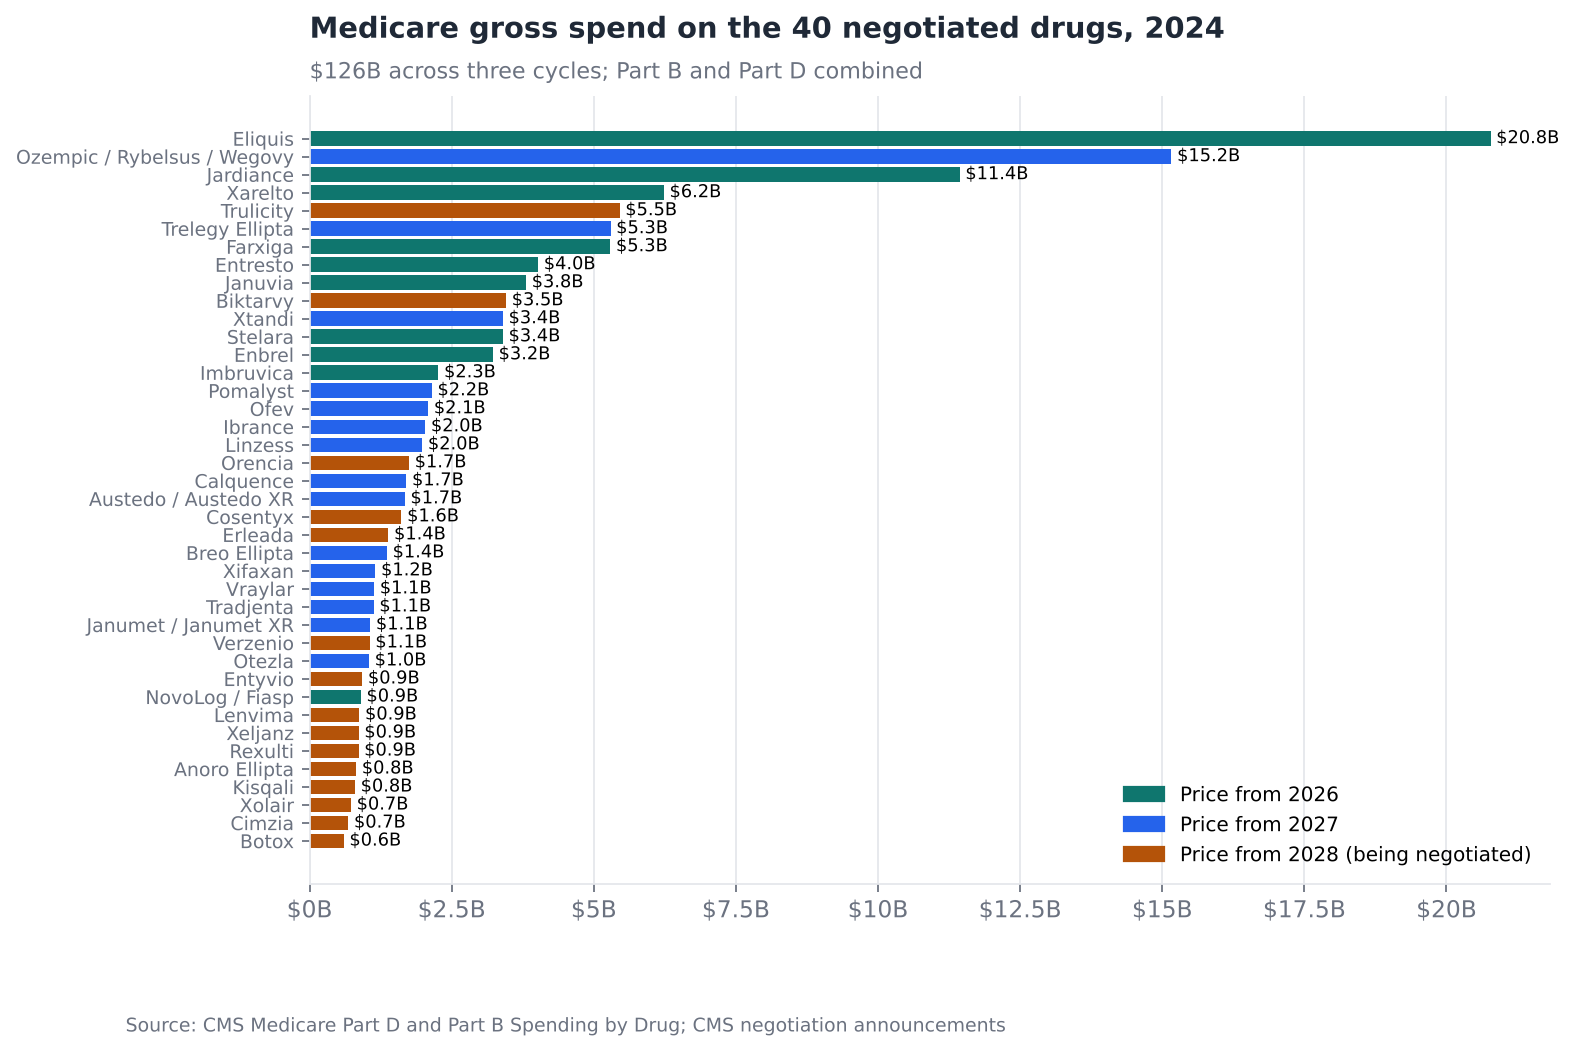

In [3]:
fig, ax = plt.subplots(figsize=(10, 6.4))
plot = by_drug.sort_values("total")
colors = plot["cycle"].map({2026: style.ACCENT, 2027: "#2563EB", 2028: style.ACCENT_2})
ax.barh(plot.index, plot["total"], color=colors)
for y, v in enumerate(plot["total"]):
    ax.text(v, y, f" ${v / 1e9:,.1f}B", va="center", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (style.ACCENT, "#2563EB", style.ACCENT_2)]
ax.legend(handles, ["Price from 2026", "Price from 2027", "Price from 2028 (being negotiated)"], loc="lower right", fontsize=9)
style.dollars(ax, "x")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
ax.set_title(f"Medicare gross spend on the 40 negotiated drugs, {Y}")
style.subtitle(ax, f"${by_cycle['total'].sum() / 1e9:,.0f}B across three cycles; Part B and Part D combined")
style.source(fig, SRC)
style.save(fig, FIG / "01_selected_drug_spend.png")

## 2. Headline price cuts versus net impact

CMS publishes each MFP next to the drug's **list price**. The list-price
discounts look dramatic (38% to 85%), but manufacturers already paid large
rebates on many of these drugs, so the true revenue loss is much smaller. CMS's
own estimate of **net** savings is the better guide:

| Cycle | Gross Part D cost (base year) | CMS net savings | Net savings ÷ gross |
|---|---|---|---|
| IPAY 2026 (10 drugs) | $56.2B (2023) | ~$6B (22% of net) | ~11% |
| IPAY 2027 (15 drugs) | $42.5B (2024) | ~$12B (44% of net) | ~28% |

Each drug's net impact is estimated by sharing out CMS's cycle total in
proportion to *gross spend × list-price discount*. A drug with more spend and a
deeper cut takes more of the loss. Lacking drug-level rebate data, this is the
most defensible public method; it assumes rebate depth is similar within a cycle.

In [4]:
rows = []
for cyc, (savings, pct, base_year, gross_base) in CMS_CYCLE_SAVINGS.items():
    sub = by_drug[by_drug["cycle"] == cyc].copy()
    base = d[d["is_overall"] & d["selected"].isin(sub.index)].groupby("selected")[f"Tot_Spndng_{base_year}"].sum()
    weight = base * sub["discount"]
    alloc = savings * weight / weight.sum()            # CMS savings shared by spend x discount
    ratio = alloc / base                               # net impact as share of gross, per drug
    sub["partD_gross_base"] = base
    sub["net_impact_ratio"] = ratio
    sub["est_annual_net_impact"] = ratio * sub["D"]    # applied to latest-year Part D spend
    rows.append(sub)
imp = pd.concat(rows)
imp["list_reduction_at_gross"] = imp["D"] * imp["discount"]
imp.sort_values("est_annual_net_impact", ascending=False).round(3).head(25)

,D,B,total,cycle,discount,condition,partD_gross_base,net_impact_ratio,est_annual_net_impact,list_reduction_at_gross
selected,,,,,,,,,,
Ozempic / Rybelsus / Wegovy,1.516166e+10,0.00,1.516166e+10,2027,0.714,"Diabetes, CV risk, obesity",1.516166e+10,0.313,4.746904e+09,1.082976e+10
Eliquis,2.077493e+10,0.00,2.077493e+10,2026,0.557,Blood clots,1.827345e+10,0.096,1.986299e+09,1.156378e+10
Trelegy Ellipta,5.294402e+09,0.00,5.294402e+09,2027,0.732,"Asthma, COPD",5.294402e+09,0.321,1.699677e+09,3.877704e+09
Jardiance,1.143600e+10,0.00,1.143600e+10,2026,0.656,"Diabetes, heart failure",8.839935e+09,0.113,1.288998e+09,7.504250e+09
Xtandi,3.400769e+09,0.00,3.400769e+09,2027,0.480,Prostate cancer,3.400769e+09,0.211,7.161200e+08,1.633782e+09
Xarelto,6.232232e+09,0.00,6.232232e+09,2026,0.619,Blood clots,6.309247e+09,0.106,6.625946e+08,3.857474e+09
Linzess,1.981959e+09,0.00,1.981959e+09,2027,0.748,"IBS-C, constipation",1.981959e+09,0.328,6.495350e+08,1.481873e+09
Farxiga,5.290549e+09,0.00,5.290549e+09,2026,0.679,"Diabetes, heart failure, CKD",4.342182e+09,0.117,6.170036e+08,3.592054e+09
Pomalyst,2.150232e+09,0.00,2.150232e+09,2027,0.602,Multiple myeloma,2.150232e+09,0.264,5.675575e+08,1.294846e+09


## 3. Manufacturer exposure

Spend is assigned to manufacturers using CMS's manufacturer-level rows. Cycle 3
(IPAY 2028) prices are not yet public, so its exposure is a range: the 25th to
75th percentile of the net-impact ratios seen in cycles 1 and 2.

In [5]:
# Part B data has no manufacturer split, so its selected drugs are assigned by hand
PARTB_MFTR = {"Orencia": "Bristol Myers Squibb", "Entyvio": "Takeda", "Botox": "AbbVie", "Xolair": "Roche",
              "Cimzia": "UCB", "Stelara": "Johnson & Johnson", "Cosentyx": "Novartis", "Enbrel": "Amgen"}


def mftr_spend(df):
    x = df[~df["is_overall"] & df["selected"].notna()]
    return x.groupby(["selected", "mftr"])[spend_col].sum()


bx = b[b["selected"].notna()].assign(mftr=lambda x: x["selected"].map(PARTB_MFTR).fillna("Other"))
partb_ms = bx.groupby(["selected", "mftr"])[spend_col].sum()
ms = pd.concat([mftr_spend(d), partb_ms]).groupby(level=[0, 1]).sum().rename("spend").reset_index()
ms = ms.merge(sel[["drug", "cycle"]], left_on="selected", right_on="drug")
ratio_by_drug = imp["net_impact_ratio"]
lo_r, mid_r, hi_r = ratio_by_drug.quantile([0.25, 0.5, 0.75])
ms["ratio_mid"] = ms["selected"].map(ratio_by_drug).fillna(mid_r)
ms["ratio_lo"] = ms["selected"].map(ratio_by_drug).fillna(lo_r)
ms["ratio_hi"] = ms["selected"].map(ratio_by_drug).fillna(hi_r)
for s in ("mid", "lo", "hi"):
    ms[f"impact_{s}"] = ms["spend"] * ms[f"ratio_{s}"]

# Consolidate CMS labeler names to parent companies for readability
PARENT = [("bristol", "Bristol Myers Squibb"), ("bms", "Bristol Myers Squibb"), ("squibb", "Bristol Myers Squibb"), ("pfizer", "Pfizer"),
          ("novo", "Novo Nordisk"), ("lilly", "Eli Lilly"), ("boehringer", "Boehringer Ingelheim"),
          ("janssen", "Johnson & Johnson"), ("johnson", "Johnson & Johnson"), ("astrazeneca", "AstraZeneca"),
          ("merck", "Merck"), ("novartis", "Novartis"), ("sandoz", "Novartis"), ("amgen", "Amgen"), ("abbvie", "AbbVie"),
          ("allergan", "AbbVie"), ("pharmacyclics", "AbbVie"), ("glaxo", "GSK"), ("gsk", "GSK"), ("astellas", "Astellas"),
          ("celgene", "Bristol Myers Squibb"), ("teva", "Teva"), ("salix", "Bausch Health"), ("bausch", "Bausch Health"),
          ("gilead", "Gilead"), ("takeda", "Takeda"), ("genentech", "Roche"), ("eisai", "Eisai"), ("otsuka", "Otsuka"),
          ("ucb", "UCB"), ("immunex", "Amgen"), ("ironwood", "AbbVie"), ("sanofi", "Sanofi")]


def parent(name: str) -> str:
    n = name.lower()
    return next((p for k, p in PARENT if k in n), name)


ms["parent"] = ms["mftr"].map(parent)
mx = ms.groupby("parent").agg(spend=("spend", "sum"), impact_mid=("impact_mid", "sum"),
                              impact_lo=("impact_lo", "sum"), impact_hi=("impact_hi", "sum"),
                              drugs=("selected", lambda s: ", ".join(sorted(set(s)))))
mx = mx.sort_values("impact_mid", ascending=False)
mx.to_csv(TAB / "manufacturer_exposure.csv")
(mx[["spend", "impact_lo", "impact_mid", "impact_hi"]] / 1e9).round(2).join(mx["drugs"]).head(12)

,spend,impact_lo,impact_mid,impact_hi,drugs
parent,,,,,
Novo Nordisk,16.01,4.86,4.86,4.86,"NovoLog / Fiasp, Ozempic / Rybelsus / Wegovy"
Bristol Myers Squibb,24.67,2.75,2.89,3.05,"Eliquis, Orencia, Pomalyst"
GSK,7.47,2.29,2.35,2.43,"Anoro Ellipta, Breo Ellipta, Trelegy Ellipta"
Boehringer Ingelheim,14.65,2.16,2.16,2.16,"Jardiance, Ofev, Tradjenta"
Johnson & Johnson,11.02,1.21,1.32,1.44,"Erleada, Stelara, Xarelto"
Eli Lilly,6.51,0.75,1.26,1.86,"Trulicity, Verzenio"
AbbVie,5.99,1.08,1.13,1.19,"Botox, Imbruvica, Linzess, Vraylar"
AstraZeneca,6.99,0.91,0.91,0.91,"Calquence, Farxiga"
Merck,4.88,0.91,0.91,0.91,"Janumet / Janumet XR, Januvia"


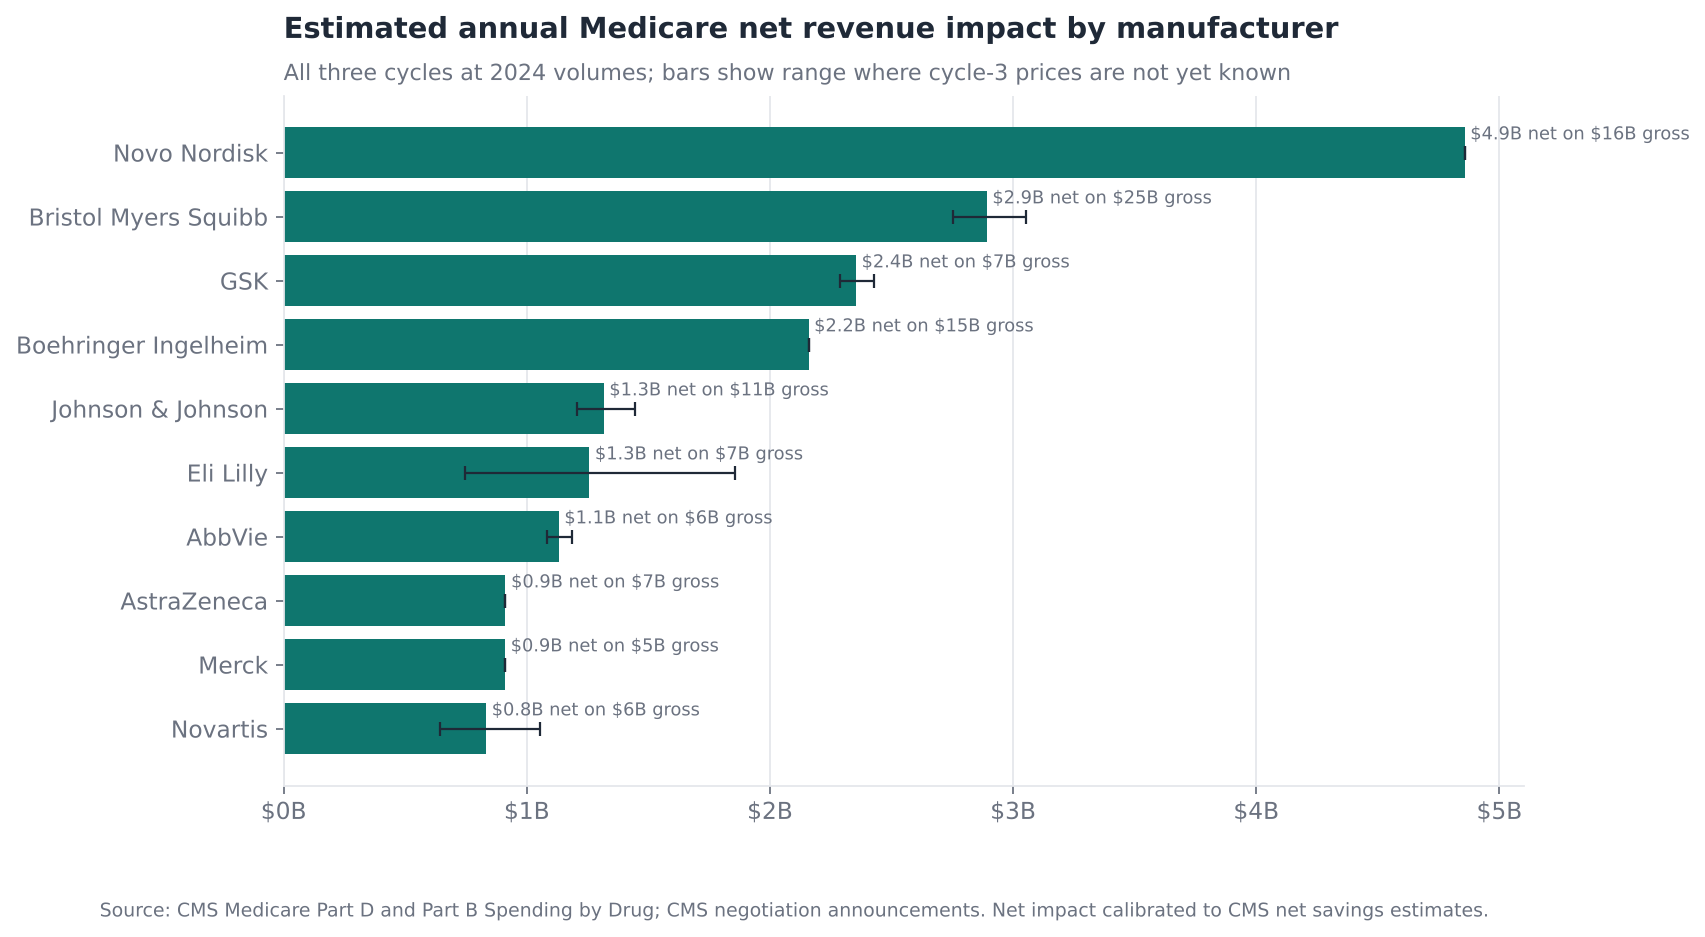

In [6]:
top = mx.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.barh(top.index, top["impact_mid"], color=style.ACCENT, label="Estimated annual net revenue impact")
ax.errorbar(top["impact_mid"], range(len(top)),
            xerr=[top["impact_mid"] - top["impact_lo"], top["impact_hi"] - top["impact_mid"]],
            fmt="none", ecolor=style.INK, elinewidth=1, capsize=3)
for y, (v, s) in enumerate(zip(top["impact_mid"], top["spend"])):
    ax.text(v, y + 0.28, f" ${v / 1e9:,.1f}B net on ${s / 1e9:,.0f}B gross", va="center", fontsize=8, color=style.MUTED)
style.dollars(ax, "x")
ax.grid(axis="y", visible=False)
ax.set_title("Estimated annual Medicare net revenue impact by manufacturer")
style.subtitle(ax, f"All three cycles at {Y} volumes; bars show range where cycle-3 prices are not yet known")
style.source(fig, SRC + ". Net impact calibrated to CMS net savings estimates.")
style.save(fig, FIG / "02_manufacturer_exposure.png")

## 4. Who is next? Screening for the February 2027 selection (IPAY 2029)

Eligibility rules applied, from the statute and CMS guidance:
1. **Time on market:** at least 7 years since first approval for a small molecule
   (NDA) or 11 years for a biologic (BLA), counted to the selection date.
2. **No generic or biosimilar on the market.** A generic is treated as marketed
   when CMS's own spending data show Medicare claims for the generic version.
   This is more reliable than FDA approvals, since many approved generics are
   blocked by patents. Marketed biosimilars are flagged by hand.
3. **Orphan drugs:** since July 2025, drugs approved only for rare diseases are
   excluded, and for drugs that later gain a common indication the clock starts
   when that indication is approved. Known cases are applied by hand below.
4. **Not already selected**, then ranked by Part B + Part D gross spend. CMS
   picks up to 15 drugs, grouping all brands of one active ingredient.

**Validation first:** run the screen as if it were January 2025, against Part D
only, and compare with the 15 drugs CMS actually picked for IPAY 2027.

In [7]:
fda = pd.read_csv(RAW / "fda_approvals.csv.gz")
fda["first_approval"] = pd.to_datetime(fda["first_approval"].astype("Int64").astype(str), format="%Y%m%d", errors="coerce")

overall = pd.concat([d[d["is_overall"]], b[b["is_overall"]]])
for df in (overall,):
    df["Brnd_Name"] = df["Brnd_Name"].str.replace(r"\*|\(.*?\)", "", regex=True).str.strip()
    df["Gnrc_Name"] = df["Gnrc_Name"].fillna("").str.replace("*", "", regex=False).str.strip()
cand = (overall.groupby(["Brnd_Name", "Gnrc_Name"])[[f"Tot_Spndng_{y}" for y in YEARS]].sum().reset_index())
cand = cand.merge(fda.drop(columns=["Gnrc_Name"], errors="ignore").drop_duplicates("Brnd_Name"), on="Brnd_Name", how="left")
cand["selected"] = cand["Brnd_Name"].map(selected_drug)
cand["sel_cycle"] = cand["selected"].map(sel.set_index("drug")["cycle"])


def moiety(name: str) -> str:
    """Active-ingredient key: first word of each component, so salts and suffixes match.
    'Fluticasone Propion/Salmeterol' and 'Fluticasone-Salmeterol' both give 'fluticasone/salmeterol'."""
    parts = re.split(r"[/]|-(?=[a-z])", str(name).lower())
    return "/".join(p.strip().split(" ")[0] for p in parts if p.strip())


cand["key"] = cand["Gnrc_Name"].map(moiety)


def marketed_generics(df, clm_col):
    """Ingredients whose generic version (a row named after the ingredient itself) has
    at least 2% of the ingredient's Medicare claims."""
    x = df.assign(key=df["Gnrc_Name"].map(moiety), bkey=df["Brnd_Name"].map(moiety),
                  clms=pd.to_numeric(df[clm_col], errors="coerce").fillna(0))
    x["is_generic"] = x["bkey"] == x["key"]
    share = x[x["is_generic"]].groupby("key")["clms"].sum() / x.groupby("key")["clms"].sum()
    return set(share[share >= 0.02].index)


qd = pd.read_csv(SHARED / "partd_quarterly_spending_by_drug.csv.gz", dtype=str)
qd = qd[(qd["Mftr_Name"].str.lower() == "overall") & qd["Year"].str.startswith(str(qd["Year"].str[:4].max()))]
GEN_BY_2024 = marketed_generics(d[d["is_overall"]], f"Tot_Clms_{Y}")
GEN_BY_LATEST = GEN_BY_2024 | marketed_generics(qd, "Tot_Clms")
print(f"Ingredients with marketed generics: {len(GEN_BY_2024)} in {Y}, {len(GEN_BY_LATEST)} by {qd['Year'].iloc[0]}")

# Biologics with marketed US biosimilars by 2026 (manual)
BIOSIMILAR = {"adalimumab", "ustekinumab", "infliximab", "pegfilgrastim", "filgrastim", "trastuzumab", "bevacizumab",
              "rituximab", "insulin", "epoetin", "denosumab", "aflibercept", "eculizumab", "natalizumab",
              "tocilizumab", "ranibizumab", "romiplostim", "omalizumab"}
# Orphan-only drugs (excluded since July 2025) and orphan-first drugs whose clock restarts at
# the first common-disease approval. Hand-coded from FDA labels; not exhaustive.
ORPHAN_ONLY = {"ruxolitinib", "tafamidis", "daratumumab", "venetoclax", "ravulizumab", "eculizumab", "zanubrutinib",
               "macitentan", "riociguat", "treprostinil", "elexacaftor"}   # PAH and cystic fibrosis drugs
ORPHAN_CLOCK = {"pembrolizumab": "2015-10-02",   # Keytruda: first non-orphan approval (NSCLC)
                "nivolumab": "2015-03-04"}      # Opdivo: first non-orphan approval (squamous NSCLC)


def screen(df, selection_date, spend_year, exclude_cycles, generics, top=15):
    """Group brands by active ingredient (CMS selects at that level), then apply the rules."""
    x = df[df["app_type"].isin(["NDA", "BLA"])].copy()
    x["spend"] = x[f"Tot_Spndng_{spend_year}"]
    g = (x.groupby("key")
          .agg(spend=("spend", "sum"), first_approval=("first_approval", "min"),
               is_bla=("app_type", lambda s: (s == "BLA").any()),
               brands=("Brnd_Name", lambda s: " / ".join(sorted(set(s))[:3])),
               lead_brand=("Brnd_Name", lambda s: s.loc[x.loc[s.index, "spend"].idxmax()]),
               selected=("selected", "first"), sel_cycle=("sel_cycle", "min"),
               sponsor=("sponsor", "first"))
          .reset_index())
    g["clock_start"] = g["first_approval"]
    for ing, dt in ORPHAN_CLOCK.items():
        g.loc[g["key"] == ing, "clock_start"] = pd.Timestamp(dt)
    yrs = (pd.Timestamp(selection_date) - g["clock_start"]).dt.days / 365.25
    g["years_on_market"] = yrs.round(1)
    g["rule_years"] = np.where(g["is_bla"], 11, 7)
    first = g["key"].str.split("/").str[0]
    ok = ((yrs >= g["rule_years"]) & ~g["key"].isin(generics)
          & ~first.isin(BIOSIMILAR) & ~first.isin(ORPHAN_ONLY) & ~g["sel_cycle"].isin(exclude_cycles))
    return g[ok].sort_values("spend", ascending=False).head(top)


spend_cols = [f"Tot_Spndng_{y}" for y in YEARS]
partd_spend = overall[overall["part"] == "D"].groupby(["Brnd_Name", "Gnrc_Name"])[spend_cols].sum()
partd_only = (cand.drop(columns=spend_cols).merge(partd_spend.reset_index(), on=["Brnd_Name", "Gnrc_Name"]))
bt = screen(partd_only, "2025-02-01", 2024, [2026], GEN_BY_2024)
actual_2027 = set(sel.loc[sel["cycle"] == 2027, "drug"])
hits = set(bt["selected"].dropna()) & actual_2027
print(f"Back-test IPAY 2027: the screen's top 15 contains {len(hits)} of the 15 drugs CMS selected")
bt[["lead_brand", "brands", "spend", "years_on_market", "selected"]].assign(spend=lambda x: (x["spend"] / 1e9).round(2))

Ingredients with marketed generics: 827 in 2024, 859 by 2026 (Q1)
Back-test IPAY 2027: the screen's top 15 contains 11 of the 15 drugs CMS selected


,lead_brand,brands,spend,years_on_market,selected
167,Ozempic,Ozempic / Rybelsus / Wegovy,15.16,7.2,Ozempic / Rybelsus / Wegovy
88,Trelegy Ellipta,Trelegy Ellipta,5.29,7.4,Trelegy Ellipta
78,Xtandi,Xtandi,3.40,12.4,Xtandi
150,Pomalyst,Pomalyst,2.15,12.0,Pomalyst
113,Creon,Creon / Zenpep,2.09,15.8,NaN
125,Ofev,Ofev,2.09,10.3,Ofev
141,Ibrance,Ibrance,2.04,10.0,Ibrance
111,Linzess,Linzess,1.98,12.4,Linzess
195,Ingrezza,Ingrezza,1.96,7.8,NaN
5,Calquence,Calquence,1.70,7.3,Calquence


In [8]:
bt2 = screen(cand, "2026-02-01", 2024, [2026, 2027], GEN_BY_LATEST)
actual_2028 = set(sel.loc[sel["cycle"] == 2028, "drug"])
hits2 = set(bt2["selected"].dropna()) & actual_2028
print(f"Back-test IPAY 2028 (Part B + D): the screen's top 15 contains {len(hits2)} of the 15 drugs CMS selected")
bt2[["lead_brand", "brands", "spend", "years_on_market", "selected"]].assign(spend=lambda x: (x["spend"] / 1e9).round(2))

Back-test IPAY 2028 (Part B + D): the screen's top 15 contains 11 of the 15 drugs CMS selected


,lead_brand,brands,spend,years_on_market,selected
61,Trulicity,Trulicity,5.45,11.4,Trulicity
26,Biktarvy,Biktarvy,3.46,8.0,Biktarvy
114,Creon,Creon / Zenpep,2.09,16.8,NaN
197,Ingrezza,Ingrezza,1.96,8.8,NaN
2,Orencia,Orencia / Orencia Clickject,1.68,20.1,Orencia
140,Tagrisso,Tagrisso,1.63,10.2,NaN
13,Erleada,Erleada,1.39,8.0,Erleada
34,Cabometyx,Cabometyx,1.22,9.8,NaN
4,Verzenio,Verzenio,1.06,8.3,Verzenio
198,Entyvio,Entyvio,0.90,11.7,Entyvio


The misses come from what public data cannot see. CMS uses a November–October
spend window and applies orphan and small-biotech exceptions case by case. The
small-biotech exception, which protected some drugs from small companies, applies
only to the first three cycles. The screen is a shortlist for analysts to
review, not an oracle.

### Forecast: likely candidates for the February 2027 selection (IPAY 2029)

In [9]:
nxt = screen(cand, "2027-02-01", Y, [2026, 2027, 2028], GEN_BY_LATEST, top=25).copy()
nxt["rank"] = range(1, len(nxt) + 1)
watch = nxt[["rank", "lead_brand", "brands", "key", "spend", "is_bla", "clock_start", "years_on_market", "sponsor"]].copy()
watch["type"] = np.where(watch.pop("is_bla"), "BLA", "NDA")
watch["spend_$B"] = (watch.pop("spend") / 1e9).round(2)
watch.to_csv(TAB / "ipay2029_watchlist.csv", index=False)
watch

,rank,lead_brand,brands,key,clock_start,years_on_market,sponsor,type,spend_$B
147,1,Keytruda,Keytruda,pembrolizumab,2015-10-02,11.3,MERCK SHARP DOHME,BLA,6.13
114,2,Creon,Creon / Zenpep,lipase/protease/amylase,2009-04-30,17.8,ABBVIE,BLA,2.09
129,3,Opdivo,Opdivo,nivolumab,2015-03-04,11.9,BRISTOL MYERS SQUIBB;BRISTOL-MYERS SQUIBB,BLA,1.98
197,4,Ingrezza,Ingrezza,valbenazine,2017-04-11,9.8,NEUROCRINE,NDA,1.96
82,5,Repatha Sureclick,Repatha Sureclick / Repatha Syringe,evolocumab,2015-08-27,11.4,AMGEN INC,BLA,1.91
140,6,Tagrisso,Tagrisso,osimertinib,2015-11-13,11.2,ASTRAZENECA,NDA,1.63
196,7,Rinvoq,Rinvoq,upadacitinib,2019-08-16,7.5,ABBVIE,NDA,1.39
34,8,Cabometyx,Cabometyx,cabozantinib/malate,2016-04-25,10.8,EXELIXIS INC,NDA,1.22
50,9,Nubeqa,Nubeqa,darolutamide,2019-07-30,7.5,BAYER HEALTHCARE,NDA,1.00
149,10,Nuplazid,Nuplazid,pimavanserin,2016-04-29,10.8,ACADIA PHARMS INC,NDA,0.66


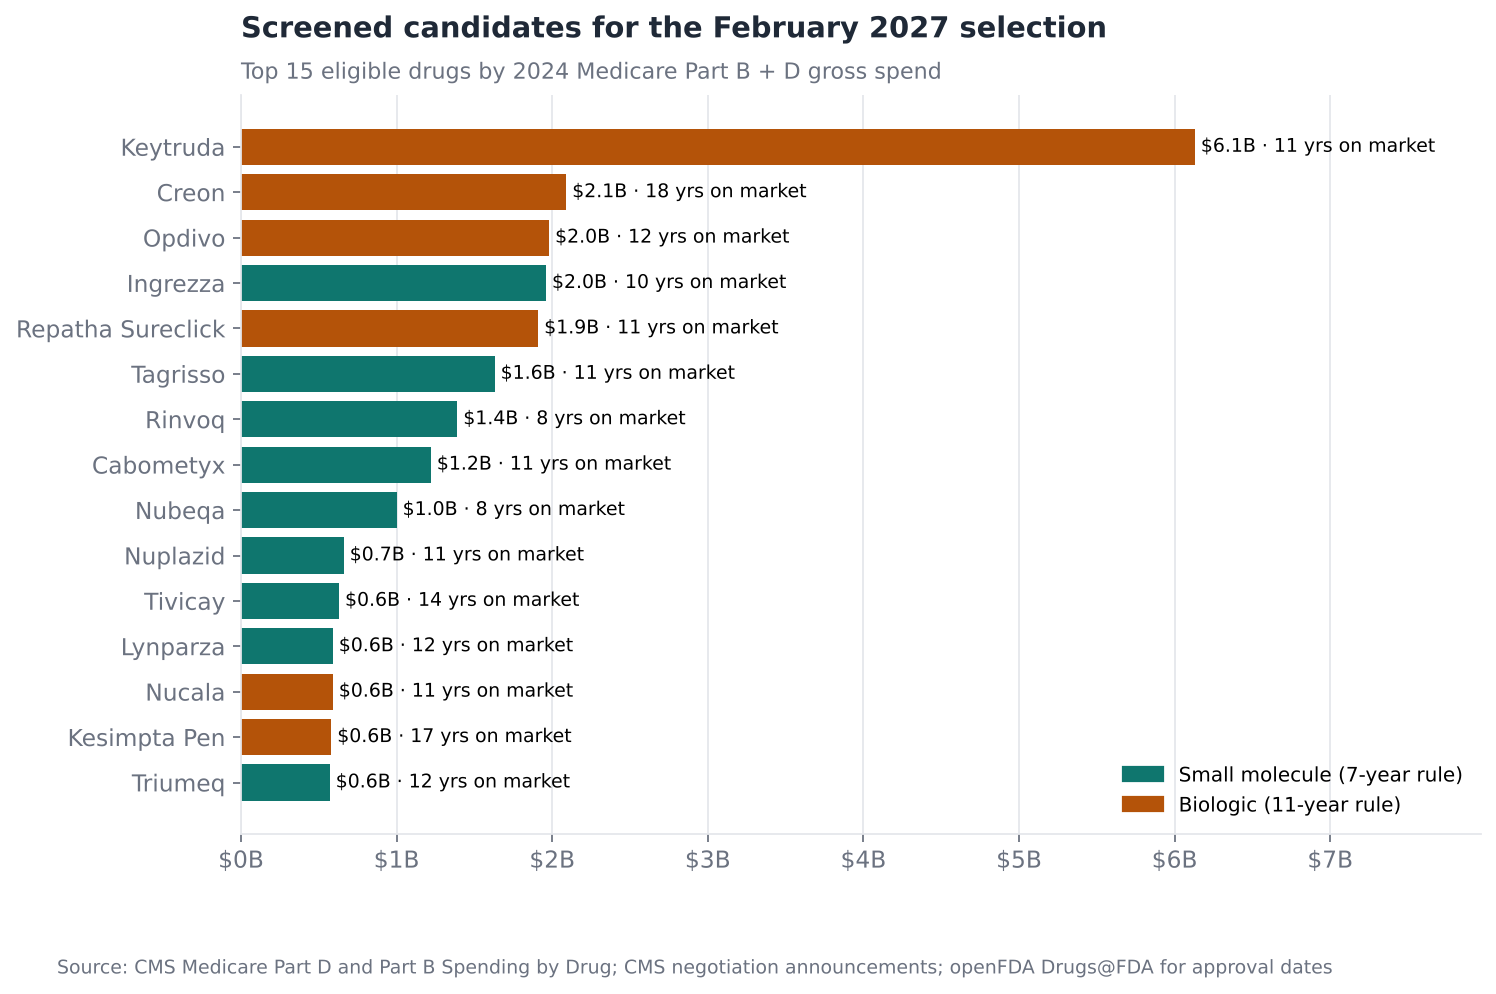

In [10]:
w = watch.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(w["lead_brand"], w["spend_$B"] * 1e9, color=[style.ACCENT_2 if t == "BLA" else style.ACCENT for t in w["type"]])
for y, (v, yrs) in enumerate(zip(w["spend_$B"], w["years_on_market"])):
    ax.text(v * 1e9, y, f" ${v:,.1f}B · {yrs:.0f} yrs on market", va="center", fontsize=8.5)
style.dollars(ax, "x")
ax.set_xlim(0, w["spend_$B"].max() * 1e9 * 1.3)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (style.ACCENT, style.ACCENT_2)]
ax.legend(handles, ["Small molecule (7-year rule)", "Biologic (11-year rule)"], loc="lower right", fontsize=9)
ax.set_title("Screened candidates for the February 2027 selection")
style.subtitle(ax, f"Top 15 eligible drugs by {Y} Medicare Part B + D gross spend")
style.source(fig, SRC + "; openFDA Drugs@FDA for approval dates")
style.save(fig, FIG / "03_ipay2029_candidates.png")

## 5. Summary numbers used in the README

In [11]:
import json
summary = {
    "spend_year": Y,
    "partD_total": float(tot["D"]), "partB_total": float(tot["B"]),
    "selected_spend_by_cycle": {int(k): float(v) for k, v in by_cycle["total"].items()},
    "selected_partD_share_by_cycle": {int(k): float(v) for k, v in by_cycle["share_of_partD"].items()},
    "net_impact_total_mid": float(mx["impact_mid"].sum()),
    "net_impact_total_range": [float(mx["impact_lo"].sum()), float(mx["impact_hi"].sum())],
    "top_manufacturers": {k: float(v) for k, v in mx["impact_mid"].head(5).items()},
    "backtest_2027_hits": len(hits), "backtest_2027_hit_names": sorted(hits),
    "backtest_2028_hits": len(hits2), "backtest_2028_hit_names": sorted(hits2),
    "watchlist_top15": watch["lead_brand"].head(15).tolist(),
    "backtest_2027_misses": sorted(actual_2027 - hits), "backtest_2028_misses": sorted(actual_2028 - hits2),
}
(TAB / "summary.json").write_text(json.dumps(summary, indent=1))
summary

{'spend_year': 2024,
 'partD_total': 288667842058.4,
 'partB_total': 52704082169.75,
 'selected_spend_by_cycle': {2026: 61355340056.81,
  2027: 42382195859.619995,
  2028: 21873687867.329998},
 'selected_partD_share_by_cycle': {2026: 0.2122701481948357,
  2027: 0.14681994210856958,
  2028: 0.06522562600225772},
 'net_impact_total_mid': 22677639761.616947,
 'net_impact_total_range': [20967197631.123173, 24692633525.39034],
 'top_manufacturers': {'Novo Nordisk': 4856985806.877512,
  'Bristol Myers Squibb': 2891492158.692929,
  'GSK': 2353530282.9730053,
  'Boehringer Ingelheim': 2158678012.6392717,
  'Johnson & Johnson': 1316107069.8318539},
 'backtest_2027_hits': 11,
 'backtest_2027_hit_names': ['Austedo / Austedo XR',
  'Calquence',
  'Ibrance',
  'Linzess',
  'Ofev',
  'Ozempic / Rybelsus / Wegovy',
  'Pomalyst',
  'Trelegy Ellipta',
  'Vraylar',
  'Xifaxan',
  'Xtandi'],
 'backtest_2028_hits': 11,
 'backtest_2028_hit_names': ['Biktarvy',
  'Cimzia',
  'Entyvio',
  'Erleada',
  'Kisqa